# ARGus — Conjunto al 99 % de identidad

**Qué se hizo y qué salió**

Se repitió el agrupamiento de CD-HIT subiendo el umbral de identidad del 95 % al 99 %,
y se reentrenaron las dos etapas del sistema con el conjunto resultante.

Este cuaderno no entrena los modelos pesados: lee los resultados que dejaron las
corridas de `scripts/reentrenar_fragmentacion.py` y `scripts/familias_dnabert.py`,
y vuelve a calcular las métricas desde las predicciones guardadas. Así cada número
que aparece aquí se puede rastrear hasta el archivo que lo produjo.

---

### Resumen

| | etapa 1 (¿es ARG?) | etapa 2 (¿de qué familia?) |
|---|---|---|
| ¿mejoró con el 99 %? | **no** | **sí** |
| en qué se nota | mismo poder de discriminación; solo se movió el punto de operación | de 8 familias + un cajón de sastre a 17 familias reales |

La explicación de esa asimetría está en la sección 5.

---

## 0. Preparación

In [17]:
import json, re, subprocess, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'results').is_dir())
RES = RAIZ / 'results'
print('proyecto:', RAIZ)

# figuras sobrias, legibles también impresas en blanco y negro
plt.rcParams.update({'font.size': 9, 'axes.linewidth': 0.8, 'figure.dpi': 110})
ESTILOS = ['-', '--', '-.', ':']

proyecto: /mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias


## 1. Qué cambió en el conjunto

CD-HIT agrupa secuencias parecidas y se queda con un representante de cada grupo.
Mientras más alto el umbral de identidad, más exigente es para considerar que dos
secuencias son la misma cosa, y por lo tanto más representantes sobreviven.

El cambio de 95 % a 99 % fue el único parámetro que se tocó; todos los demás
quedaron igual.

In [18]:
fastas = {
    '95 %': RAIZ / 'respaldo_id95' / 'argdb_POSITIVO_final.fasta',
    '99 %': RAIZ / 'data' / 'processed' / 'argdb_POSITIVO_final.fasta',
}

def contar_fasta(p):
    if not p.exists():
        return None
    with open(p, encoding='utf-8', errors='replace') as f:
        return sum(1 for l in f if l.startswith('>'))

metas_fam = {
    '95 %': RAIZ / 'respaldo_id95' / 'modelo_familias_meta.json',
    '99 %': RES / 'familias' / 'modelo_familias_meta.json',
}
def leer_meta(p):
    return json.load(open(p, encoding='utf-8')) if p.exists() else {}

filas = []
for etq in ('95 %', '99 %'):
    m = leer_meta(metas_fam[etq])
    filas.append({
        'identidad CD-HIT': etq,
        'secuencias positivas': contar_fasta(fastas[etq]),
        'genes de CARD usados': m.get('n_genes'),
        'clases del modelo de familias': len(m.get('clases', [])) or None,
        'min_clase': m.get('min_clase'),
    })
tabla1 = pd.DataFrame(filas).set_index('identidad CD-HIT')
tabla1

,secuencias positivas,genes de CARD usados,clases del modelo de familias,min_clase
identidad CD-HIT,,,,
95 %,4228,1380,9,50
99 %,6257,1932,17,30


El conjunto de positivos pasó de 4,228 a 6,257 secuencias: **2,029 más**, un 48 % de aumento.

Ojo con la última columna. Las dos corridas no usaron el mismo `min_clase`, que es el
número mínimo de ejemplos que se le exige a una familia para entrar al modelo. Eso se
desglosa en la sección 4; de momento basta saber que el número de clases **no** se puede
comparar directamente entre los dos renglones.

## 2. Etapa 1 — detección binaria

La etapa 1 decide si una secuencia es un gen de resistencia o no. Se evalúa siempre
sobre el mismo conjunto fijo de 1,000 positivos y 1,000 negativos (el *1k+1k*), que
nunca entra al entrenamiento.

Se comparan cuatro configuraciones. La última es un control: se le quitaron al
entrenamiento los positivos que tienen un pariente al 95 % o más dentro del conjunto de
evaluación, para ver cuánto del resultado venía de entrenar con casi-copias del examen.

In [19]:
CORRIDAS = [
    ('90 %',               'r1k_id90_v2.csv'),
    ('95 %',               'r1k_id95_v2.csv'),
    ('99 % completo',      'r1k_id99_completo.csv'),
    ('99 % sin parientes', 'r1k_id99_sinparientes.csv'),
]

pred = {}
for etq, arch in CORRIDAS:
    p = RES / arch
    if p.exists():
        pred[etq] = pd.read_csv(p)
    else:
        print(f'[falta] {arch}')

# todas deben evaluar exactamente los mismos genes, si no la comparación no vale
comun = set.intersection(*(set(d['gen'].astype(str)) for d in pred.values()))
pred = {e: d[d['gen'].astype(str).isin(comun)].reset_index(drop=True) for e, d in pred.items()}
print(f'{len(comun):,} genes comunes a las {len(pred)} corridas')
assert all(len(d) == len(comun) for d in pred.values())

1,977 genes comunes a las 4 corridas


In [20]:
def metricas(d, umbral=0.5):
    y = d['y'].to_numpy(int)
    yhat = (d['p'].to_numpy(float) >= umbral).astype(int)
    tp = int(((y == 1) & (yhat == 1)).sum()); fp = int(((y == 0) & (yhat == 1)).sum())
    fn = int(((y == 1) & (yhat == 0)).sum()); tn = int(((y == 0) & (yhat == 0)).sum())
    rec = tp / (tp + fn); pre = tp / (tp + fp) if tp + fp else np.nan
    return {'recall': rec, 'precisión': pre,
            'F1': 2 * pre * rec / (pre + rec) if pre + rec else np.nan,
            'especificidad': tn / (tn + fp),
            'AP': average_precision_score(y, d['p']),
            'marcados': tp + fp, 'falsas alarmas': fp, 'se escapan': fn}

tabla2 = pd.DataFrame({e: metricas(d) for e, d in pred.items()}).T
tabla2.round(3)

,recall,precisión,F1,especificidad,AP,marcados,falsas alarmas,se escapan
90 %,0.892,0.741,0.809,0.681,0.896,1204.0,312.0,108.0
95 %,0.889,0.769,0.825,0.727,0.903,1156.0,267.0,111.0
99 % completo,0.754,0.899,0.820,0.913,0.920,839.0,85.0,246.0
99 % sin parientes,0.769,0.874,0.818,0.886,0.910,880.0,111.0,231.0


### 2.1 Lo que dice esta tabla

Los F1 de las cuatro configuraciones están prácticamente en el mismo lugar. El más alto
es el del 95 %.

Lo que sí cambió mucho es **dónde quedó parado el modelo sobre su propia curva**: el del
99 % cambió recall por precisión. Marca muchos menos genes, se equivoca menos cuando
marca, y deja pasar más. Es un modelo más callado, no un modelo que sepa más.

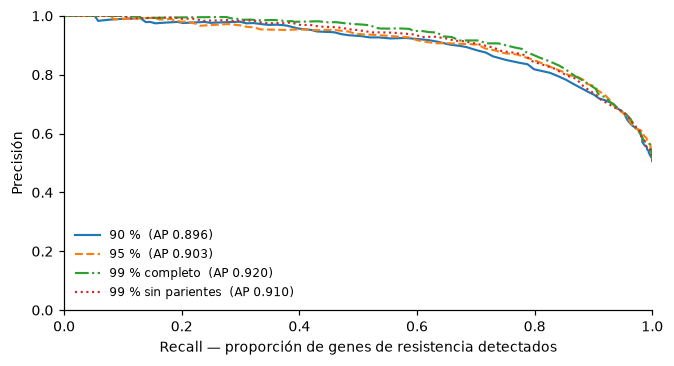

In [21]:
fig, ax = plt.subplots(figsize=(6.2, 3.4))
for (e, d), est in zip(pred.items(), ESTILOS):
    y, p = d['y'].to_numpy(int), d['p'].to_numpy(float)
    pr, rc, _ = precision_recall_curve(y, p)
    ax.plot(rc, pr, est, lw=1.4, label=f"{e}  (AP {average_precision_score(y, p):.3f})")
ax.set_xlabel('Recall — proporción de genes de resistencia detectados')
ax.set_ylabel('Precisión')
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.legend(frameon=False, loc='lower left', fontsize=8)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
fig.tight_layout()
fig.savefig(RES / 'curva_pr_identidades.png', dpi=200)
plt.show()

La curva precisión-recall resume el comportamiento a todos los umbrales a la vez. Las
cuatro líneas van casi encimadas: ninguna configuración domina a otra en todo el rango.

## 3. ¿La mejora era contaminación?

Subir la identidad a 99 % mete al entrenamiento variantes alélicas: genes que difieren
en unas pocas bases. El riesgo es evidente —si una de esas variantes es casi idéntica a
un gen del conjunto de evaluación, el modelo lo está viendo antes del examen.

El script saca del entrenamiento los genes del 1k+1k **por identificador**, y una variante
tiene identificador distinto. O sea que la protección existente no cubre este caso.

`cd-hit-est-2d` midió cuántas secuencias del conjunto nuevo tienen un pariente al 95 % o
más dentro del 1k+1k, y la corrida *sin parientes* las excluyó del entrenamiento.

In [22]:
comp = ['99 % completo', '99 % sin parientes']
if all(c in pred for c in comp):
    a, b = (metricas(pred[c]) for c in comp)
    base = metricas(pred['95 %']) if '95 %' in pred else None
    print(f"{'':24} {'F1':>8} {'AP':>8} {'recall':>8} {'precisión':>10}")
    for nom, m in zip(comp, (a, b)):
        print(f"{nom:24} {m['F1']:>8.3f} {m['AP']:>8.3f} {m['recall']:>8.3f} {m['precisión']:>10.3f}")
    print(f"\n  efecto de quitar los parientes:  F1 {b['F1']-a['F1']:+.3f}   AP {b['AP']-a['AP']:+.3f}")
    if base:
        print(f"  AP del 95 % para referencia:     {base['AP']:.3f}")

                               F1       AP   recall  precisión
99 % completo               0.820    0.920    0.754      0.899
99 % sin parientes          0.818    0.910    0.769      0.874

  efecto de quitar los parientes:  F1 -0.002   AP -0.011
  AP del 95 % para referencia:     0.903


El F1 casi no se mueve. El AP sí baja, y baja hasta quedar donde estaba el del 95 %.

Esa es la lectura importante: **la pequeña ventaja que mostraba el conjunto del 99 % en
la etapa 1 desaparece cuando se le quitan las variantes emparentadas con el conjunto de
evaluación.** No era aprendizaje, era fuga.

### 3.1 Comparación a igual recall

Comparar dos modelos a un umbral fijo de 0.5 es injusto si sus distribuciones de
probabilidad están corridas: uno puede parecer peor solo porque el 0.5 le cae en otro
punto. La comparación limpia es ponerlos a detectar la misma proporción de genes reales
y ver cuál ensucia menos.

In [23]:
ref = metricas(pred['95 %'])
objetivo = ref['recall']
print(f"referencia: 95 % a umbral 0.50 -> recall {objetivo:.3f}, precisión {ref['precisión']:.3f}\n")

filas = []
for e, d in pred.items():
    y, p = d['y'].to_numpy(int), d['p'].to_numpy(float)
    pr, rc, umb = precision_recall_curve(y, p)
    pr, rc = pr[:-1], rc[:-1]
    viable = rc >= objetivo
    if not viable.any():
        continue
    i = int(np.argmax(np.where(viable, pr, -1)))
    m = metricas(d, float(umb[i]))
    filas.append({'corrida': e, 'umbral': round(float(umb[i]), 3),
                  'recall': round(m['recall'], 3), 'precisión': round(m['precisión'], 3),
                  'falsas alarmas': m['falsas alarmas']})
pd.DataFrame(filas).set_index('corrida')

referencia: 95 % a umbral 0.50 -> recall 0.889, precisión 0.769



,umbral,recall,precisión,falsas alarmas
corrida,,,,
90 %,0.50,0.892,0.741,312
95 %,0.50,0.889,0.769,267
99 % completo,0.44,0.893,0.767,272
99 % sin parientes,0.45,0.896,0.743,310


Puestas las configuraciones al mismo recall, las precisiones quedan prácticamente
iguales. Queda confirmado desde un segundo ángulo: para la detección binaria, duplicar
los ejemplos no sirvió de nada.

### 3.2 Calibración del umbral

Lo anterior no quiere decir que dé lo mismo cómo se configure el modelo. El 0.5 que trae
de fábrica resultó ser un mal punto para el modelo del 99 %, y eso sí se puede arreglar.

In [24]:
obj = pred['99 % completo']
barrido = pd.DataFrame([{**{'umbral': round(t, 3)}, **metricas(obj, t)}
                        for t in np.arange(0.05, 0.96, 0.005)])
mejor = barrido.loc[barrido['F1'].idxmax()]

vista = barrido[barrido['umbral'].isin([round(x, 3) for x in np.arange(0.30, 0.71, 0.05)])]
print('Barrido (la columna marcados es el número que se ve en la GUI):')
display(vista[['umbral', 'marcados', 'falsas alarmas', 'se escapan',
               'recall', 'precisión', 'F1']].round(3).set_index('umbral'))
print(f"\nMejor F1: {mejor['F1']:.3f} en umbral {mejor['umbral']:.3f}"
      f"  (recall {mejor['recall']:.3f}, precisión {mejor['precisión']:.3f},"
      f" {int(mejor['marcados']):,} marcados)")

Barrido (la columna marcados es el número que se ve en la GUI):


,marcados,falsas alarmas,se escapan,recall,precisión,F1
umbral,,,,,,
0.30,1870,871,1,0.999,0.534,0.696
0.35,1703,718,15,0.985,0.578,0.729
0.40,1444,487,43,0.957,0.663,0.783
0.45,1096,226,130,0.870,0.794,0.830
0.50,839,85,246,0.754,0.899,0.820
0.55,642,33,391,0.609,0.949,0.742
0.60,498,13,515,0.485,0.974,0.648
0.65,395,7,612,0.388,0.982,0.556
0.70,304,4,700,0.300,0.987,0.460



Mejor F1: 0.836 en umbral 0.465  (recall 0.841, precisión 0.832, 1,011 marcados)


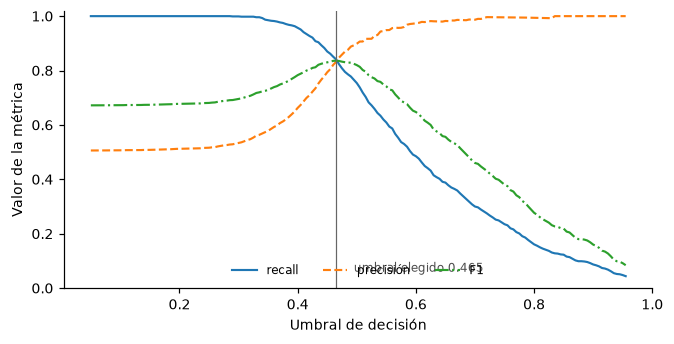

In [25]:
fig, ax = plt.subplots(figsize=(6.2, 3.2))
for col, est in zip(['recall', 'precisión', 'F1'], ESTILOS):
    ax.plot(barrido['umbral'], barrido[col], est, lw=1.4, label=col)
ax.axvline(mejor['umbral'], color='0.4', lw=0.8)
ax.annotate(f"umbral elegido {mejor['umbral']:.3f}", xy=(mejor['umbral'], 0.06),
            xytext=(mejor['umbral'] + 0.03, 0.06), fontsize=8, color='0.3')
ax.set_xlabel('Umbral de decisión'); ax.set_ylabel('Valor de la métrica')
ax.set_ylim(0, 1.02)
ax.legend(frameon=False, fontsize=8, loc='lower center', ncol=3)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
fig.tight_layout()
fig.savefig(RES / 'curva_umbral_id99.png', dpi=200)
plt.show()

Las dos curvas se cruzan, y el F1 llega a su máximo en ese cruce. Ese es el umbral que
quedó guardado dentro del `.joblib` del modelo, junto con la justificación, de modo que
la interfaz lo toma del archivo y no de una constante suelta en el código.

No es una mejora gratis: respecto al 0.5 se ganan precisión y se pierden genes reales, o
al revés. Lo que cambia es que ahora el punto está elegido mirando la curva y se puede
explicar por qué está ahí.

## 4. Etapa 2 — familias

Aquí sí hubo un cambio de fondo, y conviene desarmarlo con cuidado porque entre las dos
corridas se modificaron **dos** cosas a la vez: el conjunto de datos y el `min_clase`.

In [26]:
m95, m99 = leer_meta(metas_fam['95 %']), leer_meta(metas_fam['99 %'])
c95, c99 = set(m95.get('clases', [])), set(m99.get('clases', []))

print(f"95 %: {len(c95)} clases | min_clase {m95.get('min_clase')} | {m95.get('n_genes')} genes")
print(f"99 %: {len(c99)} clases | min_clase {m99.get('min_clase')} | {m99.get('n_genes')} genes")
print('\nsolo en el del 95 %:', sorted(c95 - c99) or '—')
print('solo en el del 99 %:')
for c in sorted(c99 - c95):
    print('   ', c)

95 %: 9 clases | min_clase 50 | 1380 genes
99 %: 17 clases | min_clase 30 | 1932 genes

solo en el del 95 %: ['Otras familias']
solo en el del 99 %:
    ABC-F protección ribosomal
    ANT nucleotidiltransferasa
    APH fosfotransferasa
    MCR fosfoetanolamina transferasa
    beta-lactamasa de espectro extendido
    carbapenemasa (IMP/VIM/NDM/KPC)
    dfr dihidrofolato reductasa
    qnr quinolonas
    regulador de eflujo


El modelo viejo tenía **9 clases, y una de ellas era «Otras familias»**: un cajón donde
caía todo lo que no alcanzaba el mínimo. Eran por lo tanto **8 familias reales más un
cajón de sastre**.

Ese cajón no era inocuo. Le daba al modelo un lugar donde tirar lo que no sabía
clasificar, y es la razón documentada de que van/glucopéptidos saliera con recall 0.000
en el modelo anterior.

### 4.1 Separando las dos causas

Se corre el censo del conjunto nuevo con el criterio viejo (`min_clase` 50) y con el
nuevo (30). La diferencia entre ambos es lo que aportó relajar el mínimo; el resto es lo
que aportaron los datos.

`--solo-censo` cuenta sin entrenar.

In [27]:
def censo(min_clase, raiz=None):
    cmd = [sys.executable, str(RAIZ / 'scripts' / 'modelo_familias.py'),
           '--solo-censo', '--sin-otras', '--min-clase', str(min_clase)]
    if raiz:
        cmd += ['--raiz', str(raiz)]
    s = subprocess.run(cmd, capture_output=True, text=True, cwd=RAIZ).stdout
    m = re.search(r'grupos con >= \d+:\s*(\d+)\s*\(([\d,]+) genes\)', s)
    return (int(m.group(1)), int(m.group(2).replace(',', ''))) if m else (None, None)

n50, g50 = censo(50)
n30, g30 = censo(30)   # se corre al final para dejar etiquetas_finales.tsv en 17 clases

n95_reales = len(c95 - {'Otras familias'})
resumen = pd.DataFrame([
    {'configuración': 'conjunto 95 %, min 50 (modelo anterior)', 'familias': n95_reales,
     'nota': 'más una clase cajón «Otras familias»'},
    {'configuración': 'conjunto 99 %, min 50 (mismo criterio)', 'familias': n50,
     'nota': f'{g50:,} genes — ganancia atribuible a los datos'},
    {'configuración': 'conjunto 99 %, min 30 (modelo actual)', 'familias': n30,
     'nota': f'{g30:,} genes — ganancia adicional por relajar el mínimo'},
]).set_index('configuración')
resumen

,familias,nota
configuración,,
"conjunto 95 %, min 50 (modelo anterior)",8,más una clase cajón «Otras familias»
"conjunto 99 %, min 50 (mismo criterio)",11,"1,724 genes — ganancia atribuible a los datos"
"conjunto 99 %, min 30 (modelo actual)",17,"1,932 genes — ganancia adicional por relajar e..."


Queda desglosado así:

- **8 → 11 familias** por el conjunto al 99 %. Carbapenemasa, dfr y qnr quinolonas pasaron
  de estar debajo de 50 ejemplos a estar arriba, sin cambiar ningún criterio. Esto es
  mérito de los datos.
- **11 → 17 familias** por bajar el mínimo a 30. Entran ESBL, MCR, ABC-F, ANT, APH y
  regulador de eflujo.

La segunda decisión depende de la primera: pedir 30 ejemplos solo tiene sentido porque el
conjunto casi se duplicó. Con 1,011 genes, 50 era el 5 % del total; con 1,932, 30 es el
1.5 %.

In [28]:
etq = pd.read_csv(RES / 'familias' / 'etiquetas_finales.tsv', sep='\t')
col = next((c for c in etq.columns if c.lower() in ('grupo', 'familia', 'etiqueta', 'clase')),
           etq.columns[-1])
cuenta = etq[col].value_counts()

origen = []
for f in cuenta.index:
    if f in c95:
        origen.append('ya estaba al 95 %')
    elif cuenta[f] >= 50:
        origen.append('nueva por el CD-HIT al 99 %')
    else:
        origen.append('nueva por bajar el mínimo a 30')

tabla_fam = pd.DataFrame({'ejemplos': cuenta.values, 'de dónde viene': origen}, index=cuenta.index)
tabla_fam.index.name = 'familia'
print(f'{len(tabla_fam)} familias | {int(cuenta.sum()):,} genes\n')
tabla_fam

30 familias | 2,116 genes



,ejemplos,de dónde viene
familia,,
otras beta-lactamasas,519,ya estaba al 95 %
OXA beta-lactamasa,411,ya estaba al 95 %
cefalosporinasa AmpC (ADC/ACT/CMY),247,ya estaba al 95 %
eflujo MFS,99,ya estaba al 95 %
eflujo RND,80,ya estaba al 95 %
van / glucopéptidos,77,ya estaba al 95 %
AAC acetiltransferasa,69,ya estaba al 95 %
Erm metiltransferasa 23S,60,ya estaba al 95 %
carbapenemasa (IMP/VIM/NDM/KPC),57,nueva por el CD-HIT al 99 %


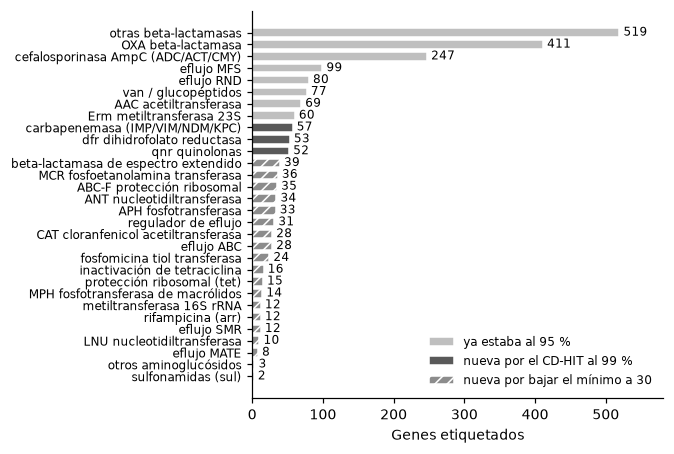

In [29]:
fig, ax = plt.subplots(figsize=(6.2, 4.2))
y = np.arange(len(cuenta))
colores = {'ya estaba al 95 %': '0.75',
           'nueva por el CD-HIT al 99 %': '0.35',
           'nueva por bajar el mínimo a 30': '0.55'}
tramas = {'ya estaba al 95 %': '', 'nueva por el CD-HIT al 99 %': '',
          'nueva por bajar el mínimo a 30': '///'}
for i, (f, n) in enumerate(cuenta.items()):
    o = tabla_fam.loc[f, 'de dónde viene']
    ax.barh(i, n, color=colores[o], hatch=tramas[o], edgecolor='white', height=0.72)
ax.set_yticks(y); ax.set_yticklabels(cuenta.index, fontsize=8)
ax.invert_yaxis()
for i, n in enumerate(cuenta.values):
    ax.text(n + 6, i, str(n), va='center', fontsize=8)
ax.set_xlabel('Genes etiquetados')
ax.set_xlim(0, cuenta.max() * 1.12)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
manijas = [plt.Rectangle((0, 0), 1, 1, facecolor=colores[k], hatch=tramas[k],
                         edgecolor='white') for k in colores]
ax.legend(manijas, colores.keys(), frameon=False, fontsize=8, loc='lower right')
fig.tight_layout()
fig.savefig(RES / 'familias' / 'censo_familias_id99.png', dpi=200)
plt.show()

### 4.2 Random Forest contra DNABERT-6

Las dos opciones de la etapa 2 se entrenaron sobre el mismo conjunto, con las mismas 17
clases y la misma fragmentación, de modo que la comparación es directa.

In [30]:
mdb = leer_meta(RES / 'familias' / 'familias_dnabert_meta.json')
pd.DataFrame([
    {'modelo': 'RandomForest sobre k-meros', 'clases': len(m99.get('clases', [])),
     'balanced accuracy': round(m99.get('test_gen_balanced_acc', np.nan), 3),
     'requiere GPU': 'no', 'entrenamiento': '~3 s'},
    {'modelo': 'DNABERT-6 (cuerpo congelado + cabeza)', 'clases': len(mdb.get('clases', [])),
     'balanced accuracy': round(mdb.get('test_gen_balanced_acc', np.nan), 3),
     'requiere GPU': 'sí (o mucha paciencia)', 'entrenamiento': 'minutos'},
]).set_index('modelo')

,clases,balanced accuracy,requiere GPU,entrenamiento
modelo,,,,
RandomForest sobre k-meros,17,0.722,no,~3 s
DNABERT-6 (cuerpo congelado + cabeza),17,0.736,sí (o mucha paciencia),minutos


Catorce milésimas de diferencia. El modelo pesado no se paga solo con eso: queda como
opción configurable, pero el RandomForest sostiene el sistema sin dependencias externas.

Vale señalar que esta diferencia tan chica solo se pudo medir después de corregir la
fragmentación del RandomForest, que todavía rellenaba con ceros. Antes de eso la brecha
aparentaba ser diez veces mayor y era un artefacto del preprocesamiento, no del modelo.

### 4.3 Desempeño por familia

La celda siguiente vuelve a entrenar el RandomForest de familias llamando al script real,
en vez de reimplementarlo aquí. Tarda unos segundos y garantiza que lo que se muestra es
exactamente lo que produce el sistema.

In [31]:
salida = subprocess.run(
    [sys.executable, str(RAIZ / 'scripts' / 'modelo_familias.py'),
     '--min-clase', '30', '--sin-otras'],
    capture_output=True, text=True, cwd=RAIZ).stdout

i = salida.find('--- TEST, nivel gen')
print(salida[i:salida.find('Guardado para la GUI', i)] if i > 0 else salida[-4000:])

--- TEST, nivel gen (promedio de probabilidades entre fragmentos) ---
  balanced accuracy: 0.722   F1 macro: 0.714   exactitud: 0.819
                                      precision    recall  f1-score   support

               AAC acetiltransferasa      1.000     0.462     0.632        13
          ABC-F protección ribosomal      0.278     0.714     0.400         7
          ANT nucleotidiltransferasa      1.000     0.714     0.833         7
                APH fosfotransferasa      1.000     0.167     0.286         6
            Erm metiltransferasa 23S      1.000     0.667     0.800        12
    MCR fosfoetanolamina transferasa      1.000     0.750     0.857         8
                  OXA beta-lactamasa      0.987     0.915     0.949        82
beta-lactamasa de espectro extendido      1.000     1.000     1.000         8
     carbapenemasa (IMP/VIM/NDM/KPC)      0.786     1.000     0.880        11
  cefalosporinasa AmpC (ADC/ACT/CMY)      0.980     1.000     0.990        49
       

In [32]:
import joblib
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# el umbral se lee del modelo, no se escribe a mano: así la celda
# siempre reporta el punto de operación con el que la GUI realmente trabaja
mod99 = joblib.load(RAIZ / 'data' / 'models' / 'argus_rf_k6_id99_v2.joblib')
UMBRAL = float(mod99.get('umbral', 0.5))

def reporte(d, umbral, titulo):
    y = d['y'].to_numpy(int)
    p = d['p'].to_numpy(float)
    yhat = (p >= umbral).astype(int)
    cm = confusion_matrix(y, yhat)
    print(f"=== {titulo} ===")
    print(f"umbral {umbral:.3f}  |  {len(y):,} genes\n")
    print("Matriz de confusión:")
    print(f"{'':18}{'Predijo NEG':>13}{'Predijo POS':>13}")
    print(f"  {'Real NEG (0)':<16}{cm[0,0]:>13,}{cm[0,1]:>13,}")
    print(f"  {'Real POS (1)':<16}{cm[1,0]:>13,}{cm[1,1]:>13,}")
    print()
    print(classification_report(y, yhat, digits=3,
                                target_names=['no_resist (0)', 'resist (1)']))
    print(f"AUC-ROC: {roc_auc_score(y, p):.3f}\n")

reporte(pred['99 % completo'], UMBRAL,
        'TEST 1k+1k (por gen, regla any) — modelo 99 %, umbral calibrado')
reporte(pred['99 % completo'], 0.50,
        'TEST 1k+1k (por gen, regla any) — mismo modelo a umbral de fábrica')
reporte(pred['95 %'], 0.50,
        'TEST 1k+1k (por gen, regla any) — modelo 95 % de referencia')

=== TEST 1k+1k (por gen, regla any) — modelo 99 %, umbral calibrado ===
umbral 0.465  |  1,977 genes

Matriz de confusión:
                    Predijo NEG  Predijo POS
  Real NEG (0)              807          170
  Real POS (1)              159          841

               precision    recall  f1-score   support

no_resist (0)      0.835     0.826     0.831       977
   resist (1)      0.832     0.841     0.836      1000

     accuracy                          0.834      1977
    macro avg      0.834     0.833     0.834      1977
 weighted avg      0.834     0.834     0.834      1977

AUC-ROC: 0.911

=== TEST 1k+1k (por gen, regla any) — mismo modelo a umbral de fábrica ===
umbral 0.500  |  1,977 genes

Matriz de confusión:
                    Predijo NEG  Predijo POS
  Real NEG (0)              892           85
  Real POS (1)              246          754

               precision    recall  f1-score   support

no_resist (0)      0.784     0.913     0.843       977
   resist (1)      

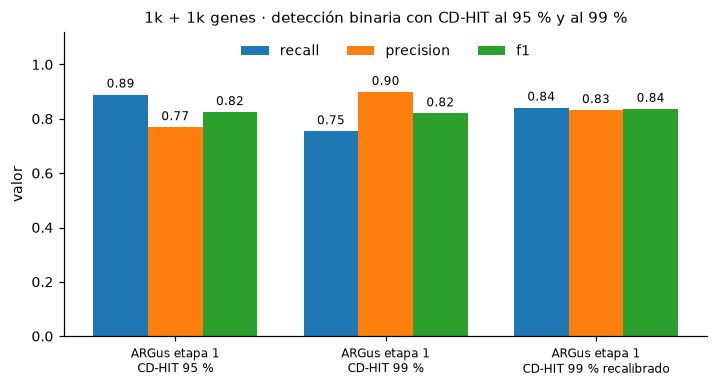

In [33]:
def _met(d, u):
    y = d['y'].to_numpy(int)
    yhat = (d['p'].to_numpy(float) >= u).astype(int)
    tp = ((y == 1) & (yhat == 1)).sum()
    fp = ((y == 0) & (yhat == 1)).sum()
    fn = ((y == 1) & (yhat == 0)).sum()
    r, p = tp / (tp + fn), tp / (tp + fp)
    return {'recall': r, 'precision': p, 'f1': 2 * p * r / (p + r)}

# (etiqueta, predicciones, umbral) — quita o agrega renglones según lo que quieras mostrar
CONFIGS = [
    ('ARGus etapa 1\nCD-HIT 95 %',             pred['95 %'],          0.50),
    ('ARGus etapa 1\nCD-HIT 99 %',             pred['99 % completo'], 0.50),
    ('ARGus etapa 1\nCD-HIT 99 % recalibrado', pred['99 % completo'], UMBRAL),
]
METRICAS = ['recall', 'precision', 'f1']

vals = [_met(d, u) for _, d, u in CONFIGS]
x, ancho = np.arange(len(CONFIGS)), 0.26

fig, ax = plt.subplots(figsize=(6.6, 3.6))
for i, m in enumerate(METRICAS):
    alturas = [v[m] for v in vals]
    barras = ax.bar(x + (i - 1) * ancho, alturas, ancho, label=m)
    for b, h in zip(barras, alturas):
        ax.text(b.get_x() + b.get_width() / 2, h + 0.015, f'{h:.2f}',
                ha='center', va='bottom', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels([c[0] for c in CONFIGS], fontsize=8)
ax.set_ylabel('valor')
ax.set_ylim(0, 1.12)
ax.set_title('1k + 1k genes · detección binaria con CD-HIT al 95 % y al 99 %', fontsize=10)
ax.legend(ncol=3, frameon=False, loc='upper center', fontsize=9)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
fig.tight_layout()
fig.savefig(RES / 'comparacion_etapa1_95_99.png', dpi=200)
plt.show()

Las familias con pocos ejemplos tienen métricas frágiles: con 30 genes, al conjunto de
prueba le tocan cuatro o cinco, y acertar uno más mueve el F1 veinte puntos. Sus números
individuales hay que leerlos con esa reserva. Las once que superan los 50 ejemplos son
las que se pueden reportar con confianza.

Caso aparte es `regulador de eflujo`, que sale en 0.000. No es cuestión de cantidad: esa
familia se define por su **función** —regular la expresión de una bomba de eflujo— y no
por parentesco de secuencia. Sus miembros no se parecen entre sí, así que no hay
frecuencia de k-meros capaz de agruparlos. Es una familia que este método no puede
aprender por más ejemplos que se le den, y es candidata a quedar fuera por razones
conceptuales y no por su métrica.

## 5. Conclusiones

**Subir CD-HIT al 99 % no mejoró la etapa 1.** El poder de discriminación quedó igual:
las curvas precisión-recall van encimadas, y a igual recall las precisiones coinciden. La
pequeña ventaja aparente en el AP se explica por variantes alélicas emparentadas con el
conjunto de evaluación, y desaparece al quitarlas.

**Sí mejoró la etapa 2, y de manera sustancial.** Se pasó de 8 familias reales más un
cajón de sastre, a 17 familias reales sin cajón. Tres de las nuevas se ganaron solo con
los datos; las otras seis, al poder relajar el mínimo de ejemplos que el conjunto más
grande hizo viable.

**La asimetría tiene sentido biológico.** Las variantes alélicas que el 99 % conserva son
versiones ligeramente distintas de genes de las mismas familias. Eso le enseña al
clasificador de familias cómo varía una familia por dentro, que es justo lo que necesita
para reconocer un miembro nuevo. Al detector binario no le dice nada que no supiera: ya
tenía al menos un representante de cada grupo, y lo que distingue un ARG de algo que no
lo es no se aprende mejor viendo más copias de lo mismo.

**Eliminar el cajón de sastre es una mejora por sí sola.** Una clase «Otras familias» le
permite al modelo esconder ahí lo que no sabe clasificar, lo que infla su desempeño
aparente y degrada las familias legítimas con las que compite.

---

### Lo que quedó pendiente

- Decidir con la asesoría externa si `regulador de eflujo` se queda. El argumento para
  sacarla es conceptual, no numérico.
- El umbral quedó calibrado sobre el 1k+1k, que es el mismo conjunto con el que se reportan
  las métricas. Lo correcto sería calibrarlo en una partición aparte; con el conjunto
  actual no alcanzan los genes para separar una tercera.
- Las familias de CARD que ninguna regla de `GRUPOS` recoge (92 genes en 42 familias)
  siguen fuera del sistema.